# Backtesting a Polymarket strategy in five minutes

`outcometick.backtest` replays a strategy against the archived order book of Polymarket's crypto Up/Down markets,
settles every market at $1 / $0 on the Chainlink stream it actually settled on, and charges the venue's taker fee.
This notebook uses the free sample day; point `run()` at a subscription download to go further back.

```bash
pip install outcometick matplotlib pandas
```

In [1]:
from outcometick import Strategy, Order
from outcometick.backtest import run, load_sample

data = load_sample("polymarket")   # downloaded once, then cached
data

'/tmp/claude-1000/-home-ligengxin-workspace-outcometick/ae55d2ba-eecb-47f3-9a4d-42d54949ff8f/scratchpad/xdg/outcometick/samples/polymarket/polymarket-data-samples'

## A strategy is a class

Hooks receive a read-only `ctx`: the book as of this event (`ctx.book()`), your position, parameters (`ctx.p`)
and a log. Returning an `Order` takes liquidity at the depth resting in the book; the market's outcome is not
visible until `on_settle`.

In [2]:
class SettlementLead(Strategy):
    """Late in the market, buy the side the settlement feed already favours."""

    params = {"enter_at_s": 60, "min_lead_bps": 2, "px_min": 0.55, "px_max": 0.95, "notional": 50}

    def on_market_open(self, ctx, market):
        self.strike, self.close, self.entry = market.strike, market.close_ts_ms, None

    def on_tick(self, ctx, tick):
        if self.entry is not None or self.strike is None:
            return None
        secs_left = (self.close - ctx.now) / 1000
        if secs_left > ctx.p.enter_at_s or secs_left <= 0:
            return None
        lead_bps = (tick.value - self.strike) / self.strike * 10_000
        if abs(lead_bps) < ctx.p.min_lead_bps:
            return None
        side = "UP" if lead_bps > 0 else "DOWN"
        ask = ctx.book().best(side)
        if ask is None or not ctx.p.px_min <= ask <= ctx.p.px_max:
            return None
        self.entry = (side, ask)
        return Order(side=side, notional=ctx.p.notional, limit=ask)

In [3]:
result = run(SettlementLead, data)
print(result.summary())

  market-days          1
  net pnl              +$82.81
  trades               57
  win rate             89.5%
  brier                0.0919
  edge/contract        3.9¢
  max drawdown         -$93.46
  fees                 -$22.36  (venue schedule, estimated per book level)
  lost to slippage     $0.00
  vs always-favourite  -$2,049.45


## Where the money came from

Calibration compares the price paid with how often that side actually won. Buckets where the realised rate sits
above the price are the edge; everything else is variance.

In [4]:
import pandas as pd
pd.DataFrame(result.report["calibration"])[["bucket", "implied", "realized", "edge_cents", "trades"]]

,bucket,implied,realized,edge_cents,trades
0,0.50-0.60,0.5500,1.0000,45.00,1
1,0.60-0.70,0.6450,0.7500,10.50,8
2,0.70-0.80,0.7500,0.3333,-41.67,3
3,0.80-0.90,0.8517,1.0000,14.83,12
4,0.90-1.00,0.9293,0.9394,1.01,33


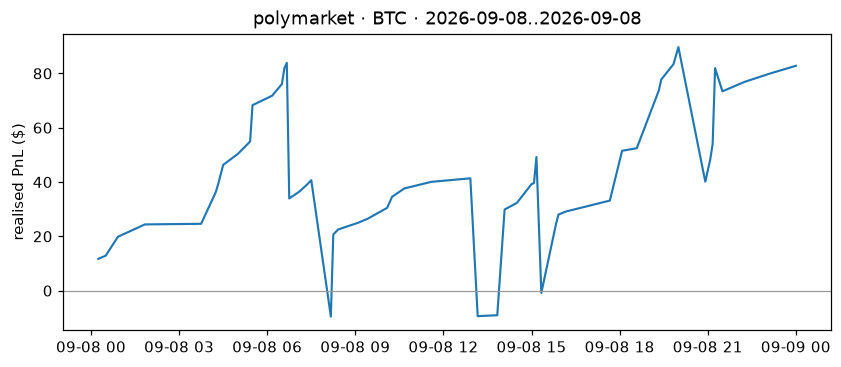

In [5]:
result.plot();

## Against the baselines, and after costs

The naive baselines buy at the opening quote at the same size and hold to settlement. Fees and latency are
part of the answer, not a footnote: the same strategy, three ways.

In [6]:
print("baselines:", result.report["baselines"])
for label, kw in [("gross, instant", {"fee_bps": 0}), ("venue fee, instant", {}), ("venue fee, +250 ms", {"latency_ms": 250})]:
    m = run(SettlementLead, data, **kw).metrics
    print(f"{label:<20} net {m['net_pnl']:>8.2f}  fees {m['fees']:>7.2f}  trades {m['trades']}")

baselines: {'always_up': -2278.67, 'always_down': -1439.43, 'always_favourite': -2049.45}
gross, instant       net   105.18  fees    0.00  trades 57
venue fee, instant   net    82.81  fees  -22.36  trades 57
venue fee, +250 ms   net    86.37  fees  -19.00  trades 48


## Every fill is there

`result.trades` and `result.fills` hold every row; `result.report["coverage"]` lists any market-day that could not
be replayed, with the reason.

In [7]:
result.trades_df().head()

,market_id,side,size,entry_px,exit_px,pnl,fees,opened_ms,closed_ms,how,outcome
0,0x9f31113a2fc8e0f7baada6205c3603e9a0d568457171...,DOWN,62.00,0.800,1.0,11.70560,0.69440,1788826440000,1.788826e+12,settled,DOWN
1,0xe6e5bea836029f15855b392a27158be0e1306591f218...,UP,19.97,0.937,1.0,1.17559,0.08252,1788827340000,1.788827e+12,settled,UP
2,0x054813dc6f7986652577c4d87c052dacbeba255602e7...,UP,57.00,0.870,1.0,6.95873,0.45127,1788828840000,1.788829e+12,settled,UP
3,0x5e5d94c664c181a93f89bbcdb959b0638f8857437490...,UP,54.00,0.910,1.0,4.55042,0.30958,1788832152000,1.788832e+12,settled,UP
4,0xafdaefd3860a4f1a3cdb3fdc87cf6bf8aec7e276faf7...,UP,5.00,0.950,1.0,0.23337,0.01663,1788839043000,1.788839e+12,settled,UP


Next: [methodology](../docs/methodology.md) for every rule the replay applies, and the
[hosted backtester](https://outcometick.com/backtest) to run the same class over recent weeks without
downloading anything.